In [1]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import json
from joblib import Parallel, delayed

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.cm as cm
import matplotlib.colors as mcolors

import seaborn as sns

import nibabel as nib

import nilearn.plotting as plotting

from scipy.stats import pearsonr, ttest_ind, mannwhitneyu, zscore, sem, f_oneway

from utils import rewrite_subjectID, process_data, correct_OS, load_maps

%load_ext autoreload
%autoreload 2

## Data loading

In [2]:
voxel_res = 1.5
root =  "/home/joan/Desktop/PROJECTS/Glioblastomas" # "D:\JoanFR_Sano"
os.makedirs(root, exist_ok=True)
MNI_DIR = "/home/joan/Documents/MNI_ICBM_2009b_NLIN_ASYM" # "C:/Users/user/Documents/Data/MNI"
atlas_lobes = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labelxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
lobe_labels = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labels.txt"
atlas_wm = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/xtract-tract-atlases-maxprob5-1mmxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
WM_labels = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/XTRACT.labels.txt"
T1_file = os.path.join(MNI_DIR, f"T1_{voxel_res}mm.nii")
T1 = nib.load(T1_file)
T1_brain = nib.load(os.path.join(MNI_DIR, f"T1_{voxel_res}mm_brain_mask.nii"))

Ni, Nj, Nk = T1.get_fdata().shape
ucsf_dir = "Glioblastoma_UCSF-PDGM_v3-20230111"
upenn_dir = "Glioblastoma_UPENN-GBM_v2-20221024"
rhuh_dir = "Glioblastoma_RHUH-GBM_v2-29102025"
tcga_dir = "Glioblastoma_TCGA-GBM_v1-20170717"
tissue = "whole"
tdmap = "TDMap-lesion"

## Other
fmt = "svg"
dpi = 300
stream_th = 0
daysXmonth = 365/12
voxel_size = (0.5**3) * (1/1000) # 0.5 (mm³/voxel) X 0.001 (cm³/mm³)   
sites = [0, 1, 2, 3]
n_jobs = 16
nthreads = 2

DATA = correct_OS(
    process_data(
        root,
        stream_th,
        voxel_size,
        UCSF_dir=ucsf_dir,
        UPENN_dir=upenn_dir,
        z_transform=0,
        cohort_ids=sites
    ),
    cohort_ids=sites,
    n_perms=10
)

ucsf_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==0]["ID"].values]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{ucsf_dir}/TDMaps_Grade-IV",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(ucsf_ids, desc="Loading UCSF maps")
)
maps_ucsf = np.vstack(results) # Nsubjects x nFeatures
maps_ucsf = np.where(maps_ucsf>=0, maps_ucsf, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

# Process and load UPENN maps
upenn_ids = DATA.loc[DATA["site"]==1]["ID"].values
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{upenn_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(upenn_ids, desc="Loading UPENN maps")
)
maps_upenn = np.vstack(results) # Nsubjects x nFeatures
maps_upenn = np.where(maps_upenn>=0, maps_upenn, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

rhuh_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==2]["ID"].values]
rhuh_ids = [sub.replace('-0', '-', 1) for sub in rhuh_ids]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{rhuh_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(rhuh_ids, desc="Loading RHUH maps")
)
maps_rhuh = np.vstack(results) # Nsubjects x nFeatures
maps_rhuh = np.where(maps_rhuh>=0, maps_rhuh, 0)

def delete_second_zero(text):
    splits = text.split('-')
    if len(splits) >= 3 and splits[2].startswith('0'):
        splits[2] = splits[2][1:]
    return '-'.join(splits)

tcga_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==3]["ID"].values]
tcga_ids = [delete_second_zero(sub) for sub in tcga_ids]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{tcga_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(tcga_ids, desc="Loading TCGA maps")
)
maps_tcga = np.vstack(results)
maps_tcga = np.where(maps_tcga>=0, maps_tcga, 0)

maps_all = np.vstack((maps_ucsf, maps_upenn, maps_rhuh, maps_tcga))

maps_training = np.vstack((maps_ucsf, maps_upenn))
maps_testing = np.vstack((maps_rhuh, maps_tcga))

Log-rank test: chi-squared statistic of 0.3129840079623018 (p=0.9575683269152051)
INFO: The effect of site was NOT found to be significant, copying OS data as it was


Loading UCSF maps:   0%|          | 0/367 [00:00<?, ?it/s]

Loading TCGA maps: 100%|██████████| 103/103 [00:00<00:00, 126.34it/s]


## Datasets

In [3]:
from dataset import Dataset
from transformer import Transformer, Projector
from lifelines import CoxPHFitter
    
import matplotlib.pyplot as plt
from pipeline_encoder import EncodingPipeline
from results_saving import save_results

In [4]:
UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1
RHUH_SITE_IDX = 3
TCGA_SITE_IDX = 2

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()
data_rhuh = DATA[DATA['site'] == RHUH_SITE_IDX].copy()
data_tcga = DATA[DATA['site'] == TCGA_SITE_IDX].copy()

data_training = pd.concat([data_ucsf, data_upenn], ignore_index=True)
data_testing = pd.concat([data_rhuh, data_tcga], ignore_index=True)

dataset_training = Dataset("ucsf+upenn", "path/1", maps_training, data_training)
dataset_testing = Dataset("rhuh+tcga", "path/2", maps_testing, data_testing)

df_training = dataset_training.df
df_testing = dataset_testing.df
training_maps = dataset_training.maps
testing_maps = dataset_testing.maps

In [5]:
duration_col = 'OS (corrected)'
event_col = 'status'

## Execute feature extraction method

In [6]:
from KernelPCA import TD_Kernel_PCA
from TractDensityComponents import TD_PCA


normalization = None
n_components= 100

# method = TD_Kernel_PCA(training_maps, T1, binary_mask=T1_brain, n_components=n_components, kernel='cosine', gamma=0.1)
method = TD_PCA(maps_training, T1, binary_mask=T1_brain, n_components=n_components)
trainer = Transformer(method)
comps_training = trainer.fit_transform(norm=normalization)
comps_testing = trainer.transform(testing_maps)

INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
INFO:	TD maps were masked.
INFO:	Transforming maps without applying any normalization . . .
INFO:	Maps transformed sucessfully!


### Prepare data

In [7]:
from data_transformer import DataTransformer


df_base = df_training
df_base = df_base.drop(columns=["OS", "site", "ID", "ltdi", "tdi", "volume"])
X_train_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_training, method, n_components=n_components)
encoding_pipeline = EncodingPipeline(X_train_with_features)
X_train = DataTransformer.feature_fit_transform(encoding_pipeline)

df_base = df_testing
df_base = df_base.drop(columns=["OS", "site", "ID", "ltdi", "tdi", "volume"])
X_test_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_testing, method, n_components=n_components)
X_test = DataTransformer.feature_transform(X_test_with_features, encoding_pipeline)

In [8]:
prefix = "PCA_Comp_"
raw_components = [col for col in X_train.columns if col.startswith(prefix)]

In [9]:
correlations = X_train[raw_components].corrwith(X_train[duration_col])
correlations.abs().sort_values(ascending=False).index

Index(['PCA_Comp_3', 'PCA_Comp_35', 'PCA_Comp_47', 'PCA_Comp_20',
       'PCA_Comp_39', 'PCA_Comp_12', 'PCA_Comp_57', 'PCA_Comp_36',
       'PCA_Comp_55', 'PCA_Comp_43', 'PCA_Comp_34', 'PCA_Comp_72',
       'PCA_Comp_19', 'PCA_Comp_11', 'PCA_Comp_6', 'PCA_Comp_76',
       'PCA_Comp_84', 'PCA_Comp_59', 'PCA_Comp_23', 'PCA_Comp_86',
       'PCA_Comp_31', 'PCA_Comp_100', 'PCA_Comp_97', 'PCA_Comp_99',
       'PCA_Comp_77', 'PCA_Comp_40', 'PCA_Comp_53', 'PCA_Comp_83',
       'PCA_Comp_78', 'PCA_Comp_4', 'PCA_Comp_29', 'PCA_Comp_2', 'PCA_Comp_79',
       'PCA_Comp_87', 'PCA_Comp_17', 'PCA_Comp_33', 'PCA_Comp_62',
       'PCA_Comp_68', 'PCA_Comp_41', 'PCA_Comp_7', 'PCA_Comp_56',
       'PCA_Comp_94', 'PCA_Comp_21', 'PCA_Comp_61', 'PCA_Comp_70',
       'PCA_Comp_89', 'PCA_Comp_66', 'PCA_Comp_85', 'PCA_Comp_26',
       'PCA_Comp_38', 'PCA_Comp_91', 'PCA_Comp_93', 'PCA_Comp_18',
       'PCA_Comp_42', 'PCA_Comp_64', 'PCA_Comp_54', 'PCA_Comp_32',
       'PCA_Comp_95', 'PCA_Comp_73', 'PCA_Comp_52',

In [10]:
clinical_columns = [col for col in X_train.columns if col not in raw_components and col not in [duration_col, event_col]]

In [13]:
current_features = components_sorted_by_correlation[:16]

# Sklejamy wszystkie potrzebne kolumny
selected_features = clinical_columns + current_features + [duration_col, event_col]

# Wycinamy podzbiory dla treningu i testu
X_train_subset = X_train[selected_features]

In [17]:
cph = CoxPHFitter(penalizer=0.01)
cph.fit(X_train_subset, duration_col, event_col)

<lifelines.CoxPHFitter: fitted with 863 total observations, 158 right-censored observations>

<lifelines.StatisticalResult: logrank_test>
               t_0 = -1
 null_distribution = chi squared
degrees_of_freedom = 1
         test_name = logrank_test

---
 test_statistic      p  -log2(p)
          44.44 <0.005     35.15

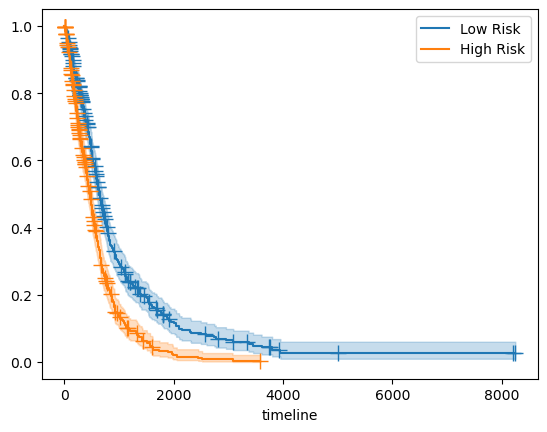

In [18]:
from lifelines import KaplanMeierFitter
import lifelines

betas_PCs = cph.params_[4:].values
PCs = X_train[current_features].values
PCS_test = X_test[current_features].values
risk_scores = np.dot(PCs, betas_PCs)
risk_scores_test = np.dot(PCS_test, betas_PCs)

p = 50
low_risk = risk_scores < np.percentile(risk_scores, p)
high_risk = risk_scores >= np.percentile(risk_scores, 100-p)
low_risk_test = risk_scores_test < np.percentile(risk_scores, p)
high_risk_test = risk_scores_test >= np.percentile(risk_scores, 100-p)

kmf_low = KaplanMeierFitter()
kmf_high = KaplanMeierFitter()
kmf_low.fit(df_training[low_risk][duration_col], event_observed=df_training[low_risk][event_col], label='Low Risk')
kmf_high.fit(df_training[high_risk][duration_col], event_observed=df_training[high_risk][event_col], label='High Risk')
kmf_low.plot_survival_function(show_censors=True)#, at_risk_counts=True)
kmf_high.plot_survival_function(show_censors=True)#, at_risk_counts=True)

lifelines.statistics.logrank_test(
    df_training[low_risk][duration_col],
    df_training[high_risk][duration_col],
    event_observed_A=df_training[low_risk][event_col],
    event_observed_B=df_training[high_risk][event_col]
).print_summary()

In [23]:
daysXmonth = 365 / 12
kmf_low.median_survival_time_ #/ daysXmonth, kmf_high.median_survival_time_ / daysXmonth

641.5236718749989

In [25]:
kmf_high.confidence_interval_

,High Risk_lower_0.95,High Risk_upper_0.95
0.000000,1.000000,1.000000
4.017894,0.983683,0.999674
6.000000,0.983683,0.999674
10.000000,0.983683,0.999674
14.000000,0.983683,0.999674
...,...,...
2055.822205,0.005721,0.038128
2449.575774,0.003548,0.032589
2520.558560,0.001712,0.026852
3076.367170,0.000401,0.021095


<lifelines.StatisticalResult: logrank_test>
               t_0 = -1
 null_distribution = chi squared
degrees_of_freedom = 1
         test_name = logrank_test

---
 test_statistic    p  -log2(p)
           1.27 0.26      1.94

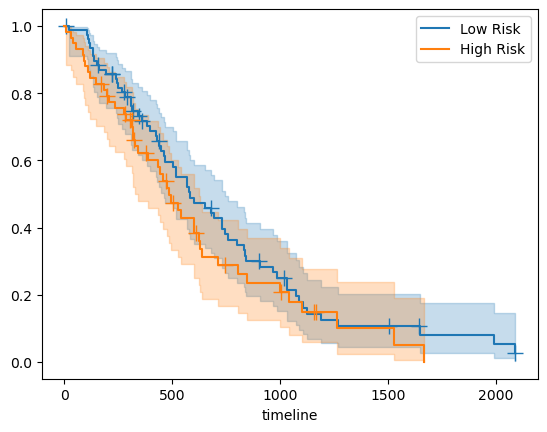

In [16]:
kmf_high_test = KaplanMeierFitter()
kmf_low_test = KaplanMeierFitter()
kmf_low_test.fit(df_testing[low_risk_test][duration_col], event_observed=df_testing[low_risk_test][event_col], label='Low Risk')
kmf_high_test.fit(df_testing[high_risk_test][duration_col], event_observed=df_testing[high_risk_test][event_col], label='High Risk')
kmf_low_test.plot_survival_function(show_censors=True, )
kmf_high_test.plot_survival_function(show_censors=True) 

lifelines.statistics.logrank_test(
    df_testing[low_risk_test][duration_col],
    df_testing[high_risk_test][duration_col],
    event_observed_A=df_testing[low_risk_test][event_col],
    event_observed_B=df_testing[high_risk_test][event_col]
).print_summary()

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter

# =========================================================
# 1. PRZYGOTOWANIE I KORELACJA PEARSONA
# =========================================================
prefix = "PCA_Comp_" # Zmień na swój prefiks (np. "cosine_Comp_") jeśli używasz KernelPCA

# Wyciągamy wszystkie surowe kolumny komponentów
raw_components = [col for col in X_train.columns if col.startswith(prefix)]

print(f"Obliczam korelacje Pearsona dla {len(raw_components)} komponentów...")

# Obliczamy korelację Pearsona każdego komponentu z kolumną przeżycia
correlations = X_train[raw_components].corrwith(X_train[duration_col])

# Sortujemy po wartości bezwzględnej (od najsilniejszego związku do najsłabszego)
components_sorted_by_correlation = correlations.abs().sort_values(ascending=False).index.tolist()

print("\nTop 5 komponentów z najwyższą korelacją z OS:")
for comp in components_sorted_by_correlation[:5]:
    print(f"{comp}: {correlations[comp]:.4f}")
print("-" * 50)

# Wyciągamy kolumny kliniczne
clinical_columns = [col for col in X_train.columns if col not in raw_components and col not in [duration_col, event_col]]

# =========================================================
# 2. GŁÓWNA PĘTLA INKREMENTALNA
# =========================================================
history_k = []
history_train_ci = []
history_test_ci = []
betas = []


# Pętla idzie po naszej idealnie posortowanej liście
for k in range(1, len(components_sorted_by_correlation) + 1):
    
    # Bierzemy k najważniejszych komponentów wg korelacji Pearsona
    current_features = components_sorted_by_correlation[:k]
    
    # Sklejamy wszystkie potrzebne kolumny
    selected_features = clinical_columns + current_features + [duration_col, event_col]
    
    # Wycinamy podzbiory dla treningu i testu
    X_train_subset = X_train[selected_features]
    X_test_subset = X_test[selected_features]
    
    # Inicjalizacja modelu z drobną karą (zapobiega błędom numerycznym przy dużej liczbie cech)
    cph = CoxPHFitter(penalizer=0.01)
    
    try:
        cph.fit(X_train_subset, duration_col, event_col)
    except Exception as e:
        print(f"Błąd przy dopasowywaniu dla k={k} komponentów: {e}")
        continue
        
    # Ocena modelu
    train_c_index = cph.concordance_index_
    c_index_test = cph.score(X_test_subset, "concordance_index")
    
    # Zapis historii do wykresu
    history_k.append(k)
    history_train_ci.append(train_c_index)
    history_test_ci.append(c_index_test)

    # Przygotowanie wyników do zapisu w CSV
    results = {
        "extraction_method": "PCA-Pearson-Sorted", 
        "training_dataset": dataset_training.name,
        "testing_dataset": dataset_testing.name,
        "n_pca_components": k,  
        "cox_method": "CoxPHFitter (Incremental)",
        "ci_training": round(train_c_index, 5),
        "ci_testing": round(c_index_test, 5),
        "covariates": clinical_columns + current_features,
        "duration_col": duration_col,
        "event_col": event_col
    }

    # PAMIĘTAJ O ZMIANIE ŚCIEŻKI ZAPISU!
    # save_results(results, "results/pca_incremental_pearson_lifelines.csv")
    
    print(f"Dodano: {k:03d} (ostatni: {current_features[-1]}) | Train CI: {train_c_index:.4f} | Test CI: {c_index_test:.4f}")

# =========================================================
# 3. GENEROWANIE WYKRESU KRZYWEJ UCZENIA
# =========================================================


Obliczam korelacje Pearsona dla 100 komponentów...

Top 5 komponentów z najwyższą korelacją z OS:
PCA_Comp_3: -0.1102
PCA_Comp_35: -0.0904
PCA_Comp_47: -0.0889
PCA_Comp_20: -0.0737
PCA_Comp_39: -0.0725
--------------------------------------------------
Dodano: 001 (ostatni: PCA_Comp_3) | Train CI: 0.6562 | Test CI: 0.6094
Dodano: 002 (ostatni: PCA_Comp_35) | Train CI: 0.6593 | Test CI: 0.6175
Dodano: 003 (ostatni: PCA_Comp_47) | Train CI: 0.6602 | Test CI: 0.6212
Dodano: 004 (ostatni: PCA_Comp_20) | Train CI: 0.6606 | Test CI: 0.6175
Dodano: 005 (ostatni: PCA_Comp_39) | Train CI: 0.6610 | Test CI: 0.6136
Dodano: 006 (ostatni: PCA_Comp_12) | Train CI: 0.6633 | Test CI: 0.6170
Dodano: 007 (ostatni: PCA_Comp_57) | Train CI: 0.6623 | Test CI: 0.6091
Dodano: 008 (ostatni: PCA_Comp_36) | Train CI: 0.6627 | Test CI: 0.6133
Dodano: 009 (ostatni: PCA_Comp_55) | Train CI: 0.6633 | Test CI: 0.6137
Dodano: 010 (ostatni: PCA_Comp_43) | Train CI: 0.6664 | Test CI: 0.6286
Dodano: 011 (ostatni: PCA_Co

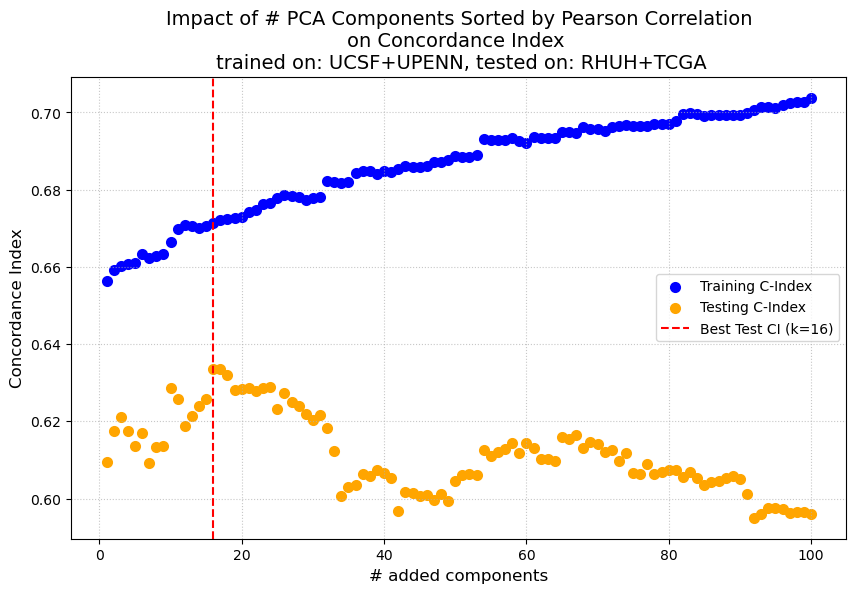

In [12]:
if history_k:
    plt.figure(figsize=(10, 6))
    plt.scatter(history_k, history_train_ci, label='Training C-Index', color='blue', linewidth=2)
    plt.scatter(history_k, history_test_ci, label='Testing C-Index', color='orange', linewidth=2)
    
    plt.title(f"Impact of # PCA Components Sorted by Pearson Correlation\non Concordance Index \n trained on: {dataset_training.name.upper()}, tested on: {dataset_testing.name.upper()}", fontsize=14)
    plt.xlabel("# added components", fontsize=12)
    plt.ylabel("Concordance Index", fontsize=12)
    
    # Find the point where the Test CI was the highest
    best_k_idx = np.argmax(history_test_ci)
    plt.axvline(x=history_k[best_k_idx], color='red', linestyle='--', 
                label=f'Best Test CI (k={history_k[best_k_idx]})')
    
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)
    
    # Save the plot
    # plt.savefig("incremental-kernel-pca/pca_incremental_pearson_curve.png", bbox_inches='tight')
    plt.show()

In [19]:
components_sorted_by_correlation[:32]

['PCA_Comp_3',
 'PCA_Comp_35',
 'PCA_Comp_47',
 'PCA_Comp_20',
 'PCA_Comp_39',
 'PCA_Comp_12',
 'PCA_Comp_57',
 'PCA_Comp_36',
 'PCA_Comp_55',
 'PCA_Comp_43',
 'PCA_Comp_34',
 'PCA_Comp_72',
 'PCA_Comp_96',
 'PCA_Comp_76',
 'PCA_Comp_19',
 'PCA_Comp_11',
 'PCA_Comp_6',
 'PCA_Comp_59',
 'PCA_Comp_98',
 'PCA_Comp_84',
 'PCA_Comp_23',
 'PCA_Comp_31',
 'PCA_Comp_100',
 'PCA_Comp_99',
 'PCA_Comp_77',
 'PCA_Comp_85',
 'PCA_Comp_40',
 'PCA_Comp_53',
 'PCA_Comp_86',
 'PCA_Comp_78',
 'PCA_Comp_4',
 'PCA_Comp_29']

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter

# =========================================================
# 1. NAME CONFIGURATION (Change the prefix if it's different!)
# =========================================================
# If your columns are "cosine_Comp_1", enter "cosine_Comp_"
# If "KernelPCA_Comp_1", enter "KernelPCA_Comp_"
prefix = "PCA_Comp_" 

# Find the total number of components with this prefix in the training set
max_components = sum([1 for col in X_train.columns if col.startswith(prefix)])

# Safely generate names in perfect order (1, 2, 3...)
kpca_columns = [f"{prefix}{i}" for i in range(1, max_components + 1) if f"{prefix}{i}" in X_train.columns]

# Extract clinical columns (everything that is not KPCA and not time/event)
clinical_columns = [col for col in X_train.columns if col not in kpca_columns and col not in [duration_col, event_col]]

# Lists to collect results for the final plot
history_k = []
history_train_ci = []
history_test_ci = []

print(f"Let's start! Detected {len(kpca_columns)} Kernel PCA components.")
print(f"Clinical features: {clinical_columns}")
print("-" * 50)

# =========================================================
# 2. MAIN INCREMENTAL LOOP
# =========================================================
for k in range(1, len(kpca_columns) + 1):
    
    # Take the first k Kernel PCA components
    current_kpca_features = kpca_columns[:k]
    
    # Combine the list of all features for this step
    selected_features = clinical_columns + current_kpca_features + [duration_col, event_col]
    
    # Subset only the selected columns
    X_train_subset = X_train[selected_features]
    X_test_subset = X_test[selected_features]
    
    # Initialize the model with a small L2 penalty for numerical stability
    cph = CoxPHFitter(penalizer=0.01)
    
    try:
        cph.fit(X_train_subset, duration_col, event_col)
    except Exception as e:
        print(f"Error fitting for k={k} components: {e}")
        continue
        
    # Evaluate the model
    train_c_index = cph.concordance_index_
    c_index_test = cph.score(X_test_subset, "concordance_index")
    
    # Save history for the plot
    history_k.append(k)
    history_train_ci.append(train_c_index)
    history_test_ci.append(c_index_test)

    # Prepare results for the file
    results = {
        "extraction_method": "KernelPCA-Cosine", # You can change this depending on the kernel used
        "training_dataset": dataset_training.name,
        "testing_dataset": dataset_testing.name,
        "n_pca_components": k,  
        "cox_method": "CoxPHFitter (Incremental)",
        "ci_training": round(train_c_index, 5),
        "ci_testing": round(c_index_test, 5),
        "covariates": clinical_columns + current_kpca_features,
        "duration_col": duration_col,
        "event_col": event_col
    }

    # REMEMBER TO CHANGE THE FOLDER WHERE YOU WANT TO SAVE THE CSV!
    save_results(results, "incremental-kernel-pca/kpca_incremental_lifelines.csv")
    
    # Print progress
    print(f"Added components: {k:03d} | Train CI: {train_c_index:.4f} | Test CI: {c_index_test:.4f}")

# =========================================================
# 3. GENERATE LEARNING CURVE PLOT
# =========================================================

Let's start! Detected 100 Kernel PCA components.
Clinical features: ['sex', 'age', 'EOR', 'MGMT']
--------------------------------------------------
Added components: 001 | Train CI: 0.6484 | Test CI: 0.6190
Added components: 002 | Train CI: 0.6517 | Test CI: 0.6127
Added components: 003 | Train CI: 0.6593 | Test CI: 0.6416
Added components: 004 | Train CI: 0.6598 | Test CI: 0.6421
Added components: 005 | Train CI: 0.6604 | Test CI: 0.6452
Added components: 006 | Train CI: 0.6606 | Test CI: 0.6453
Added components: 007 | Train CI: 0.6608 | Test CI: 0.6464
Added components: 008 | Train CI: 0.6606 | Test CI: 0.6466
Added components: 009 | Train CI: 0.6605 | Test CI: 0.6467
Added components: 010 | Train CI: 0.6602 | Test CI: 0.6482
Added components: 011 | Train CI: 0.6589 | Test CI: 0.6523
Added components: 012 | Train CI: 0.6611 | Test CI: 0.6524
Added components: 013 | Train CI: 0.6613 | Test CI: 0.6541
Added components: 014 | Train CI: 0.6611 | Test CI: 0.6558
Added components: 015 | T

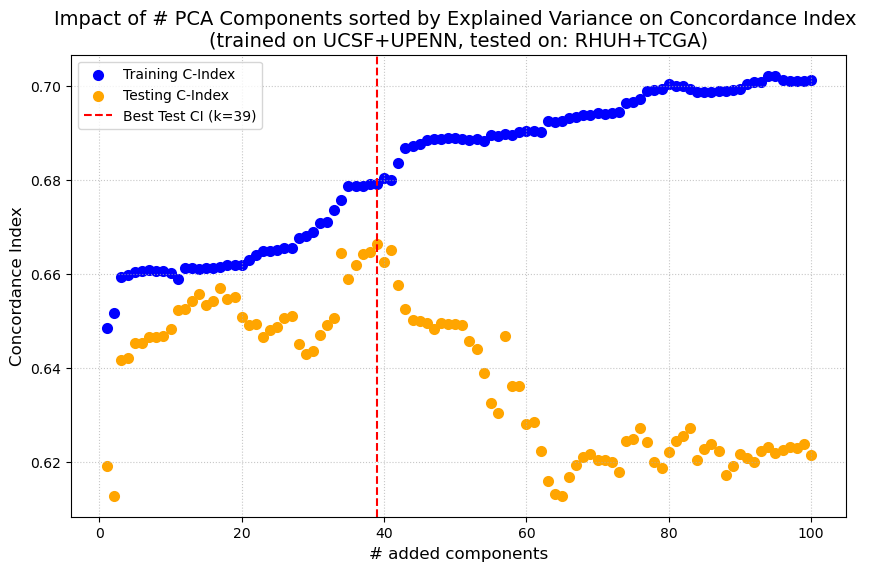

In [41]:
if history_k: # Ensure the loop actually ran
    plt.figure(figsize=(10, 6))
    plt.scatter(history_k, history_train_ci, label='Training C-Index', color='blue', linewidth=2)
    plt.scatter(history_k, history_test_ci, label='Testing C-Index', color='orange', linewidth=2)
    
    plt.title(f"Impact of # PCA Components sorted by Explained Variance on Concordance Index \n(trained on {dataset_training.name.upper()}, tested on: {dataset_testing.name.upper()})", fontsize=14)
    plt.xlabel("# added components", fontsize=12)
    plt.ylabel("Concordance Index", fontsize=12)
    
    # Find the point where Test CI was the highest and draw a vertical red line there
    best_k_idx = np.argmax(history_test_ci)
    plt.axvline(x=history_k[best_k_idx], color='red', linestyle='--', 
                label=f'Best Test CI (k={history_k[best_k_idx]})')
    
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)
    
    # Save the plot (make sure the folder exists)
    # plt.savefig("results-kernel-pca/kpca_incremental_curve.png", bbox_inches='tight')
    plt.show()

In [15]:
X_train_with_features

,sex,age,status,EOR,MGMT,OS (corrected),PCA_Comp_1,PCA_Comp_2,PCA_Comp_3,PCA_Comp_4,...,PCA_Comp_91,PCA_Comp_92,PCA_Comp_93,PCA_Comp_94,PCA_Comp_95,PCA_Comp_96,PCA_Comp_97,PCA_Comp_98,PCA_Comp_99,PCA_Comp_100
0,1,68.00,1.0,1.0,0.0,389.000000,-16643.373244,32698.229294,13183.280548,14957.362440,...,-130.012590,-399.152151,-180.132115,82.133079,209.307359,682.894549,-244.463970,-502.049805,-372.162302,-120.923726
1,0,66.00,1.0,1.0,0.0,1303.000000,-20570.360419,-11048.571977,-7199.669148,-1180.429588,...,-69.118294,-428.232966,-813.138982,-608.500578,-4.883419,240.654343,-764.952188,-195.440851,-601.256802,154.153213
2,0,70.00,1.0,1.0,0.0,185.000000,37217.628452,-20862.911303,10637.246885,399.118695,...,-317.322900,-545.642692,-137.983687,-459.121254,-99.217205,274.585205,969.047375,-83.446609,-80.796912,-11.654212
3,1,68.00,0.0,1.0,2.0,133.000000,40230.905730,11106.030017,18444.007223,-11636.928769,...,-1015.835032,-566.521757,332.587335,-291.477942,-585.007488,-51.402095,-791.307174,54.903177,-467.791235,-278.193512
4,1,64.00,1.0,1.0,2.0,313.000000,-22694.636451,36421.846251,22849.867693,-10947.721127,...,-76.633761,-8.381550,-331.444991,-595.665806,-166.827008,-517.214413,-685.032789,-483.495346,285.999490,-657.212002
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
858,0,60.38,1.0,2.0,0.0,2096.001141,-27246.426521,-19413.949688,20793.147033,5356.546472,...,-102.739879,-134.522314,-231.559384,-506.359159,-246.537527,375.366386,54.250625,-667.716697,368.233466,-401.831903
859,1,79.90,1.0,1.0,2.0,891.972370,-32265.065456,-5643.682524,-343.821160,-7951.875535,...,-41.027110,-43.450215,-31.178442,76.620237,28.296698,-71.729399,549.996323,-244.293105,902.477707,6.322179
860,1,68.15,1.0,1.0,2.0,1372.780300,-30543.354210,7816.533384,18165.239653,-21653.326068,...,468.913177,-416.655441,314.488384,868.860794,-306.303290,-514.844176,302.177482,9.297375,-357.249139,62.255633
861,0,58.09,1.0,1.0,NaN,737.953117,-27677.577022,-9799.888219,-7300.197490,-7541.857710,...,-569.823852,77.085657,-459.671956,-496.897258,487.570533,171.409816,-35.583380,557.568006,-46.134257,264.841295


Rozpoczynam inkrementalne testowanie 100 komponentów PCA...
Dodano komponentów: 001 | Train CI: 0.6484 | Test CI: 0.6190
Dodano komponentów: 002 | Train CI: 0.6517 | Test CI: 0.6127
Dodano komponentów: 003 | Train CI: 0.6593 | Test CI: 0.6416
Dodano komponentów: 004 | Train CI: 0.6598 | Test CI: 0.6421
Dodano komponentów: 005 | Train CI: 0.6604 | Test CI: 0.6452
Dodano komponentów: 006 | Train CI: 0.6606 | Test CI: 0.6453
Dodano komponentów: 007 | Train CI: 0.6608 | Test CI: 0.6464
Dodano komponentów: 008 | Train CI: 0.6606 | Test CI: 0.6466
Dodano komponentów: 009 | Train CI: 0.6605 | Test CI: 0.6467
Dodano komponentów: 010 | Train CI: 0.6602 | Test CI: 0.6482
Dodano komponentów: 011 | Train CI: 0.6589 | Test CI: 0.6523
Dodano komponentów: 012 | Train CI: 0.6611 | Test CI: 0.6524
Dodano komponentów: 013 | Train CI: 0.6613 | Test CI: 0.6541
Dodano komponentów: 014 | Train CI: 0.6611 | Test CI: 0.6558
Dodano komponentów: 015 | Train CI: 0.6612 | Test CI: 0.6533
Dodano komponentów: 016 |

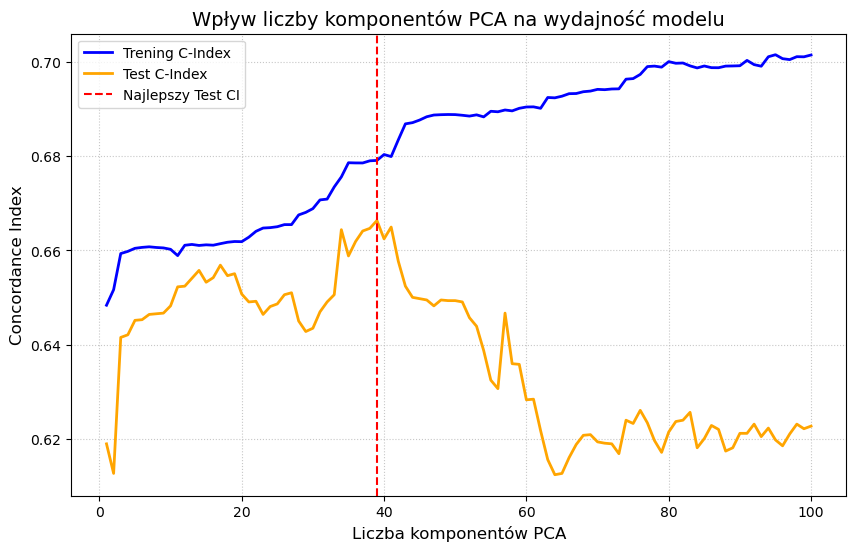

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter

# 1. Definiujemy nazwy naszych kolumn
# Bezpieczne generowanie nazw w idealnej kolejności od 1 do 100
pca_columns = [f"PCA_Comp_{i}" for i in range(1, 101) if f"PCA_Comp_{i}" in X_train.columns]

# Wyciągamy kolumny kliniczne (wszystko, co nie jest PCA, czasem ani zdarzeniem)
clinical_columns = [col for col in X_train.columns if col not in pca_columns and col not in [duration_col, event_col]]

# Listy do zbierania wyników do końcowego wykresu
history_k = []
history_train_ci = []
history_test_ci = []

print(f"Rozpoczynam inkrementalne testowanie {len(pca_columns)} komponentów PCA...")

# 2. Główna pętla inkrementalna
for k in range(1, len(pca_columns) + 1):
    
    # Bierzemy k pierwszych komponentów (np. dla k=3 weźmie PCA_1, PCA_2, PCA_3)
    current_pca_features = pca_columns[:k]
    
    # Sklejamy listę wszystkich cech dla tego kroku (kliniczne + k komponentów PCA + kolumny celu)
    selected_features = clinical_columns + current_pca_features + [duration_col, event_col]
    
    # Wycinamy tylko te kolumny z naszych zbiorów
    X_train_subset = X_train[selected_features]
    X_test_subset = X_test[selected_features]
    
    # INICJALIZACJA MODELU
    # UWAGA: Zostawiam minimalny penalizer! Przy 100 cechach lifelines prawie na pewno 
    # wyrzuci błąd macierzy osobliwej (LinAlgError). Ten mały dodatek go przed tym uchroni.
    cph = CoxPHFitter(penalizer=0.01)
    
    try:
        cph.fit(X_train_subset, duration_col, event_col)
    except Exception as e:
        print(f"Błąd przy dopasowywaniu dla k={k} komponentów: {e}")
        continue
        
    # Ocena
    train_c_index = cph.concordance_index_
    c_index_test = cph.score(X_test_subset, "concordance_index")
    
    # Zapisujemy historię do wykresu
    history_k.append(k)
    history_train_ci.append(train_c_index)
    history_test_ci.append(c_index_test)

    # Zapis wyników do słownika i CSV (tak jak robiłaś to wcześniej)
    results = {
        "extraction_method": "PCA",
        "training_dataset": dataset_training.name,
        "testing_dataset": dataset_testing.name,
        "n_pca_components": k,  # <--- Zapisujemy ile komponentów użyliśmy!
        "cox_method": "CoxPHFitter (Incremental)",
        "ci_training": round(train_c_index, 5),
        "ci_testing": round(c_index_test, 5),
        "covariates": clinical_columns + current_pca_features,
        "duration_col": duration_col,
        "event_col": event_col
    }

    save_results(results, "results-pca/pca_incremental_lifelines.csv")
    print(f"Dodano komponentów: {k:03d} | Train CI: {train_c_index:.4f} | Test CI: {c_index_test:.4f}")

# 3. Opcjonalnie: Wykres podsumowujący cały eksperyment po zakończeniu pętli!
plt.figure(figsize=(10, 6))
plt.plot(history_k, history_train_ci, label='Trening C-Index', color='blue', linewidth=2)
plt.plot(history_k, history_test_ci, label='Test C-Index', color='orange', linewidth=2)
plt.title("Wpływ liczby komponentów PCA na wydajność modelu", fontsize=14)
plt.xlabel("Liczba komponentów PCA", fontsize=12)
plt.ylabel("Concordance Index", fontsize=12)
plt.axvline(x=history_k[np.argmax(history_test_ci)], color='red', linestyle='--', label='Najlepszy Test CI')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.savefig("results-pca/pca_incremental_curve.png", bbox_inches='tight')
plt.show()

## CoxPHFitter lifelines

In [14]:
from lifelines import CoxPHFitter


penalizers = np.arange(0.001, 1.5, 0.1)
l1_ratios = np.arange(0.001, 1, 0.1)


for penalizer in penalizers:
    for l1_ratio in l1_ratios:
        cph = CoxPHFitter(penalizer=penalizer, l1_ratio=l1_ratio)
        try:
            cph.fit(X_train, duration_col, event_col)
        except Exception as e:
            print(f"Error fitting CoxPHFitter with penalizer={penalizer} and l1_ratio={l1_ratio}: {e}")
            continue

        train_c_index = cph.concordance_index_
        c_index_test = cph.score(X_test, "concordance_index")

        fig, ax = plt.subplots(figsize=(12, 20))
        ax.set_title(f"Baseline model trained on {dataset_training.name.upper()}.\n Penalizer: {penalizer:.4f}\n Training Concordance Index on {dataset_training.name.upper()}: {cph.concordance_index_:.4f} \n Testing Concordance Index on {dataset_testing.name.upper()}: {c_index_test:.4f}")
        cph.plot(ax = ax)
        plot_filename = f"results-pca/pca-100-comps-lifelines/cox_plot_penalizer_{penalizer:.3f}_l1_ratio_{l1_ratio:.3f}.png"
        fig.savefig(plot_filename, bbox_inches='tight')
        plt.close(fig)

        clean_covariates = [col for col in X_train.columns if col not in [duration_col, event_col]]
        results = {
            "extraction_method": "PCA",
            "training_dataset": dataset_training.name,
            "testing_dataset": dataset_testing.name,
            "penalizer": penalizer,
            "l1_ratio": l1_ratio,
            "cox_method": "CoxPHFitter",
            "ci_training": round(train_c_index, 5),
            "ci_testing": round(c_index_test, 5),
            "covariates": clean_covariates,
            "duration_col": duration_col,
            "event_col": event_col
        }

        save_results(results, "results-pca/pca_100_components_lifelines.csv")

## Scikit-survival ridge regression

### Prepare datasets for scikit-survival input format

In [15]:
y_train = np.array(
    list(zip(X_train[event_col].astype(bool), X_train[duration_col])),
    dtype=[('Status', '?'), ('Time', '<f8')]
)

y_test = np.array(
    list(zip(X_test[event_col].astype(bool), X_test[duration_col])),
    dtype=[('Status', '?'), ('Time', '<f8')]
)
X_train = X_train.drop(columns=[event_col, duration_col])
X_test = X_test.drop(columns=[event_col, duration_col])

In [17]:
def plot(cph_fitter, ax, plot_filename, title):
    coef_df = pd.DataFrame({
            "Feature": X_train.columns,
            "Coefficient": cph_fitter.coef_
    })
        
    coef_df = coef_df.sort_values(by="Coefficient", ascending=True)
        
    # colors = ['#2ecc71' if c < 0 else '#e74c3c' for c in coef_df["Coefficient"]]
    
    ax.barh(coef_df["Feature"], coef_df["Coefficient"], edgecolor="black", alpha=0.8)
    ax.axvline(x=0, color='black', linestyle='--', linewidth=1.5)

    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel("Coefficient weights (Log Hazard Ratio)", fontsize=12, fontweight='bold')
    ax.set_ylabel("Features", fontsize=12, fontweight='bold')
    ax.grid(True, axis='x', linestyle=':', alpha=0.7)

    fig.savefig(plot_filename, bbox_inches='tight')
    plt.close(fig)

In [ ]:
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis


alphas = 10.0 ** np.linspace(-4, 4, 100)

for alpha in alphas:
        cph_ridge = CoxPHSurvivalAnalysis(alpha=alpha)
        try:
            cph_ridge.fit(X_train, y_train)
        except Exception as e:
            print(f"Error fitting CoxPHSurvivalAnalysis with alpha={alpha}: {e}")
            continue
        
        train_c_index = cph_ridge.score(X_train, y_train)
        c_index_test = cph_ridge.score(X_test, y_test)

        fig, ax = plt.subplots(figsize=(12, 20))
        title = (
            f"Coefficient Weights (Trained on {dataset_training.name.upper()})\n"
            f"Alpha: {alpha:.4f}\n"
            f"Train C-Index: {train_c_index:.4f} | Test C-Index: {c_index_test:.4f}"
        )
        plot_filename = f"results-pca/pca-100-comps-sksurv-ridge/cox_plot_alpha_{alpha:.3f}.png"
        plot(cph_ridge, ax, plot_filename, title)

        clean_covariates = [col for col in X_train.columns if col not in [duration_col, event_col]]
        results = {
            "extraction_method": "PCA",
            "training_dataset": dataset_training.name,
            "testing_dataset": dataset_testing.name,
            "alpha": alpha,
            "cox_method": "CoxPHSurvivalAnalysis",
            "ci_training": round(train_c_index, 5),
            "ci_testing": round(c_index_test, 5),
            "covariates": clean_covariates,
            "duration_col": duration_col,
            "event_col": event_col
        }

        save_results(results, "results-pca/pca_100_comps_scikit_surv_ridge.csv")

In [19]:
def plot_2(cph_fitter, alpha, ax, plot_filename, train_c_index, c_index_test):
    import numpy as np
    
    coefficients = np.ravel(cph_fitter.coef_)
    
    coef_df = pd.DataFrame({
        "Feature": X_train.columns,
        "Coefficient": coefficients
    })
    
    coef_df = coef_df.sort_values(by="Coefficient", ascending=True)
    
    # colors = ['#2ecc71' if c < 0 else '#e74c3c' for c in coef_df["Coefficient"]]
    ax.barh(coef_df["Feature"], coef_df["Coefficient"], edgecolor="black", alpha=0.8)
    ax.axvline(x=0, color='black', linestyle='--', linewidth=1.5)

    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel("Coefficient weights (Log Hazard Ratio)", fontsize=12, fontweight='bold')
    ax.set_ylabel("Features", fontsize=12, fontweight='bold')
    ax.grid(True, axis='x', linestyle=':', alpha=0.7)

    fig.savefig(plot_filename, bbox_inches='tight')
    plt.close(fig)

In [20]:
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis



clean_covariates = [col for col in X_train.columns if col not in [duration_col, event_col]]

alphas = 10.0 ** np.linspace(-4, 4, 100)
l1_ratios = np.arange(0.001, 1, 0.1)

for alpha in alphas:
    for l1_ratio in l1_ratios:
        cph = CoxnetSurvivalAnalysis(l1_ratio=l1_ratio, alphas=[alpha])
        try:
            cph.fit(X_train, y_train)
        except Exception as e:
            print(f"Error fitting CoxnetSurvivalAnalysis with alpha={alpha}: {e}")
            continue
        
        train_c_index = cph.score(X_train, y_train)
        c_index_test = cph.score(X_test, y_test)

        fig, ax = plt.subplots(figsize=(12, 20))
        title = (
            f"Coefficient Weights (Trained on {dataset_training.name.upper()})\n"
            f"Alpha: {alpha:.4f} | L1 Ratio: {l1_ratio:.4f}\n"
            f"Train C-Index: {train_c_index:.4f} | Test C-Index: {c_index_test:.4f}"
        )
        plot_filename = f"results-pca/pca-100-comps-sksurv-elastic/cox_plot_l1_ratio_{l1_ratio:.3f}_alphas_{alpha:.3f}.png"
        plot_2(cph, alpha, ax, plot_filename, train_c_index, c_index_test)

        results = {
            "extraction_method": "KernelPCA-Cosine",
            "training_dataset": dataset_training.name,
            "testing_dataset": dataset_testing.name,
            "alpha": alpha,
            "l1_ratio": l1_ratio,
            "cox_method": "CoxnetSurvivalAnalysis",
            "ci_training": round(train_c_index, 5),
            "ci_testing": round(c_index_test, 5),
            "covariates": clean_covariates,
            "duration_col": duration_col,
            "event_col": event_col
        }

        save_results(results, "results-pca/pca-100-comps-sksurv-elastic.csv")

/tmp/ipykernel_662146/1529810318.py:14: UserWarning: all coefficients are zero, consider decreasing alpha.
  cph.fit(X_train, y_train)
/tmp/ipykernel_662146/1529810318.py:14: UserWarning: all coefficients are zero, consider decreasing alpha.
  cph.fit(X_train, y_train)
/tmp/ipykernel_662146/1529810318.py:14: UserWarning: all coefficients are zero, consider decreasing alpha.
  cph.fit(X_train, y_train)
/tmp/ipykernel_662146/1529810318.py:14: UserWarning: all coefficients are zero, consider decreasing alpha.
  cph.fit(X_train, y_train)
/tmp/ipykernel_662146/1529810318.py:14: UserWarning: all coefficients are zero, consider decreasing alpha.
  cph.fit(X_train, y_train)
/tmp/ipykernel_662146/1529810318.py:14: UserWarning: all coefficients are zero, consider decreasing alpha.
  cph.fit(X_train, y_train)
/tmp/ipykernel_662146/1529810318.py:14: UserWarning: all coefficients are zero, consider decreasing alpha.
  cph.fit(X_train, y_train)
/tmp/ipykernel_662146/1529810318.py:14: UserWarning: al

In [21]:
from sksurv.ensemble import RandomSurvivalForest


clean_covariates = [col for col in X_train.columns if col not in [duration_col, event_col]]

n_estimators = np.arange(100, 1500, 100)
min_samples_leaf = np.arange(25, 80, 5)
min_samples_split = np.arange(5, 20, 5)

for n_est in n_estimators:
    for min_leafs in min_samples_leaf:
        for min_split in min_samples_split:
            rsf = RandomSurvivalForest(
                n_estimators=n_est, min_samples_split=min_split, min_samples_leaf=min_leafs, n_jobs=-1
            )
            try:
                rsf.fit(X_train, y_train)
            except Exception as e:
                print(f"Error fitting RandomSurvivalForest with n_estimators={n_est}: {e}")
                continue
        
            train_c_index = rsf.score(X_train, y_train)
            c_index_test = rsf.score(X_test, y_test)


            results = {
                "extraction_method": "KernelPCA-Cosine",
                "training_dataset": dataset_training.name,
                "testing_dataset": dataset_testing.name,
                "n_estimators": n_est,
                "min_samples_leaf": min_leafs,
                "min_samples_split": min_split,
                "cox_method": "RandomSurvivalForest",
                "ci_training": round(train_c_index, 5),
                "ci_testing": round(c_index_test, 5),
                "covariates": clean_covariates,
                "duration_col": duration_col,
                "event_col": event_col
            }

            save_results(results, "results-pca/pca-100-comps-scikit-random-forest.csv")

## Permutation importance

In [23]:
from sklearn.inspection import permutation_importance
from sksurv.ensemble import RandomSurvivalForest


rsf = RandomSurvivalForest(
    n_estimators=400, min_samples_split=10, min_samples_leaf=25, n_jobs=-1,
)
rsf.fit(X_train, y_train)
result = permutation_importance(rsf, X_test, y_test, n_repeats=5, random_state=20, n_jobs=-1)

: 

In [ ]:
pd.DataFrame(
    {
        k: result[k]
        for k in (
            "importances_mean",
            "importances_std",
        )
    },
    index=X_test.columns,
).sort_values(by="importances_mean", ascending=False)